# Aviation Accidents Analysis

This notebook analyzes the cleaned data, separates aircraft at 20 persons aboard, compares injury and destruction outcomes, and evaluates weather and phase of flight. Minimum sample thresholds and 95% confidence intervals are used to support robust comparisons.

In [37]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

def grouped_summary(data, group_col, outcome_col, min_n=10):
    s = (data.dropna(subset=[group_col,outcome_col]).groupby(group_col)[outcome_col]
         .agg(n="count", mean="mean", std="std"))
    s = s[s["n"] >= min_n].copy()
    s["se"] = s["std"] / np.sqrt(s["n"])
    s["ci95_low"] = (s["mean"] - 1.96*s["se"]).clip(lower=0)
    s["ci95_high"] = (s["mean"] + 1.96*s["se"]).clip(upper=1)
    return s.sort_values(["mean","n"], ascending=[True,False])

## Exploratory Data Analysis  
- Load in the cleaned data

In [38]:
path = Path("data/AviationData_Cleaned.csv")
if not path.exists():
    raise FileNotFoundError("Run Aviation_Accidents_Cleaning.ipynb first.")
df = pd.read_csv(path, low_memory=False, parse_dates=["Event.Date"])
print("Shape:", df.shape)
display(df.head())
display(df[["Persons.Aboard","Fatal.Serious.Injury.Fraction","Aircraft.Destroyed"]].describe())

Shape: (17879, 13)


,Event.Date,Make,Model,Plane.Type,Aircraft.Destroyed,Persons.Aboard,Fatal.Serious.Injuries,Fatal.Serious.Injury.Fraction,Engine.Type,Weather.Condition,Number.of.Engines,Purpose.of.flight,Broad.phase.of.flight
0,1983-03-18,BOEING,747,BOEING | 747,0.0,588.0,0.0,0.0,Turbo Fan,Vmc,4.0,NaN,Taxi
1,1983-03-20,PIPER,PA-28-140,PIPER | PA-28-140,1.0,2.0,2.0,1.0,Reciprocating,Imc,1.0,Personal,Cruise
2,1983-04-02,DE HAVILLAND,DHC-6,DE HAVILLAND | DHC-6,NaN,5.0,1.0,0.2,Turbo Prop,Vmc,2.0,Skydiving,Standing
3,1983-11-08,BOEING,727-200,BOEING | 727-200,0.0,100.0,0.0,0.0,Turbo Fan,Vmc,3.0,NaN,Taxi
4,1983-11-13,BEECH,C35,BEECH | C35,0.0,1.0,0.0,0.0,Reciprocating,Vmc,1.0,Personal,Climb


,Persons.Aboard,Fatal.Serious.Injury.Fraction,Aircraft.Destroyed
count,17843.000000,17103.000000,16733.000000
mean,9.220367,0.275232,0.109185
std,37.602939,0.426685,0.311881
min,0.000000,0.000000,0.000000
25%,1.000000,0.000000,0.000000
50%,2.000000,0.000000,0.000000
75%,2.000000,0.666667,0.000000
max,588.000000,1.000000,1.000000


## Explore safety metrics across models/makes
Aircraft with fewer than 20 persons aboard are small; aircraft with 20 or more are large.

In [39]:
analysis_df = df[df["Persons.Aboard"].gt(0)].copy()
analysis_df["Aircraft.Size"] = np.where(analysis_df["Persons.Aboard"] < 20, "Small", "Large")
small = analysis_df[analysis_df["Aircraft.Size"].eq("Small")].copy()
large = analysis_df[analysis_df["Aircraft.Size"].eq("Large")].copy()
display(analysis_df["Aircraft.Size"].value_counts())

Aircraft.Size
Small    16225
Large      878
Name: count, dtype: int64

#### Analyzing Makes
The 15 makes with the lowest mean fatal/serious injury fractions are shown for each size group. A minimum of 20 usable records per make-size group is applied.

,n,mean,std,se,ci95_low,ci95_high
Make,,,,,,
MCDONNELL DOUGLAS,30,0.094048,0.227523,0.041540,0.012630,0.175466
BOEING,272,0.141973,0.318262,0.019297,0.104150,0.179796
AVIAT AIRCRAFT INC,76,0.164474,0.350125,0.040162,0.085756,0.243191
MAULE,215,0.164806,0.346926,0.023660,0.118432,0.211180
GRUMMAN ACFT ENG COR-SCHWEIZER,58,0.206897,0.408619,0.053654,0.101734,0.312059
AYRES,51,0.215686,0.415390,0.058166,0.101680,0.329692
STINSON,129,0.216408,0.377382,0.033227,0.151284,0.281533
AVIAT,70,0.221429,0.395955,0.047326,0.128670,0.314187
BELLANCA,219,0.222603,0.400462,0.027061,0.169564,0.275642


,n,mean,std,se,ci95_low,ci95_high
Make,,,,,,
MCDONNELL DOUGLAS,53,0.007827,0.017439,0.002395,0.003132,0.012522
BOMBARDIER INC,44,0.028038,0.151327,0.022813,0.000000,0.072752
BOEING,547,0.056771,0.213786,0.009141,0.038855,0.074687
BOMBARDIER,21,0.063701,0.224088,0.048900,0.000000,0.159545
EMBRAER,78,0.065274,0.219517,0.024855,0.016557,0.113991
AIRBUS,118,0.086249,0.265125,0.024407,0.038411,0.134086


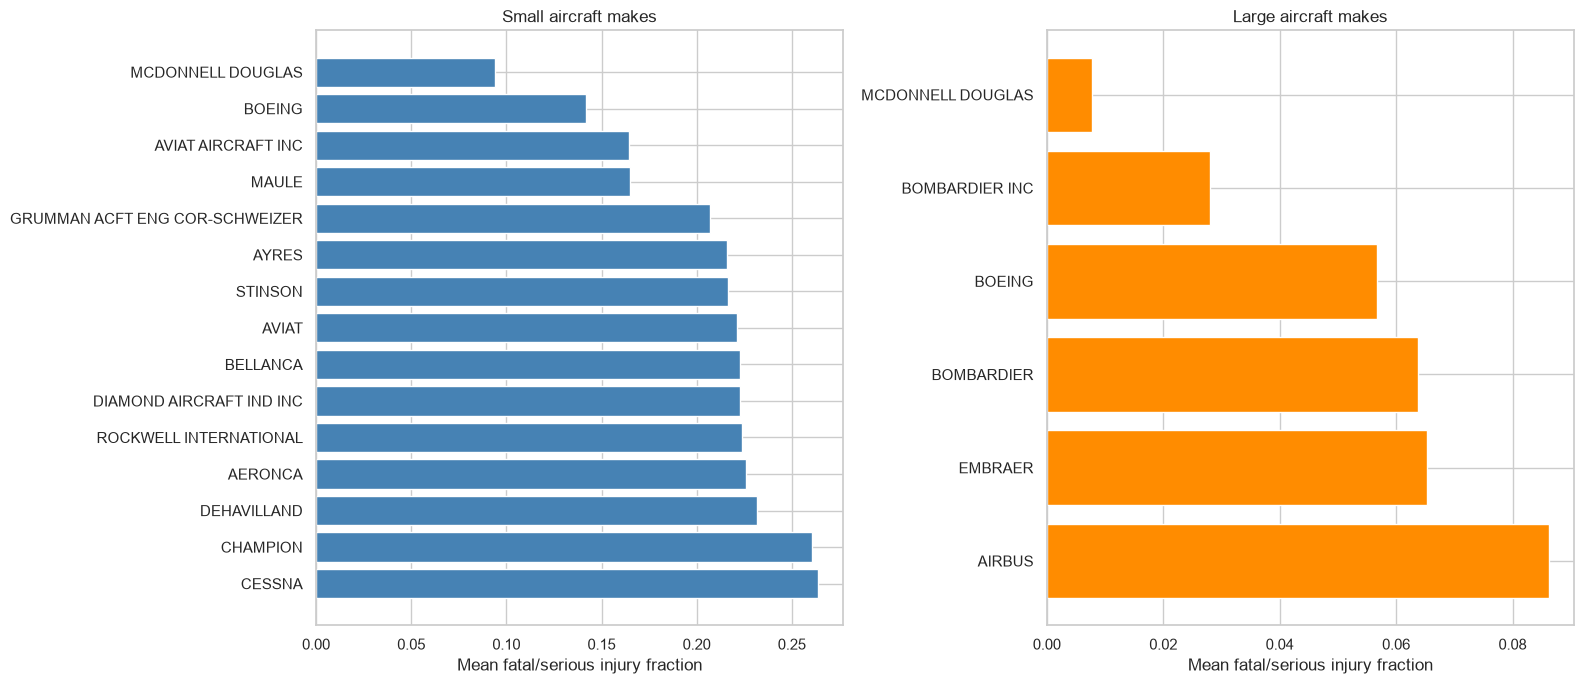

In [40]:
small_make = grouped_summary(small,"Make","Fatal.Serious.Injury.Fraction",20).head(15)
large_make = grouped_summary(large,"Make","Fatal.Serious.Injury.Fraction",20).head(15)
display(small_make); display(large_make)
fig,axes=plt.subplots(1,2,figsize=(16,7))
for ax,s,title,color in [(axes[0],small_make,"Small aircraft makes","steelblue"),(axes[1],large_make,"Large aircraft makes","darkorange")]:
    p=s.reset_index().sort_values("mean",ascending=False)
    ax.barh(p["Make"],p["mean"],color=color); ax.set_title(title); ax.set_xlabel("Mean fatal/serious injury fraction")
plt.tight_layout(); plt.show()

**Distribution of injury rates: small makes**

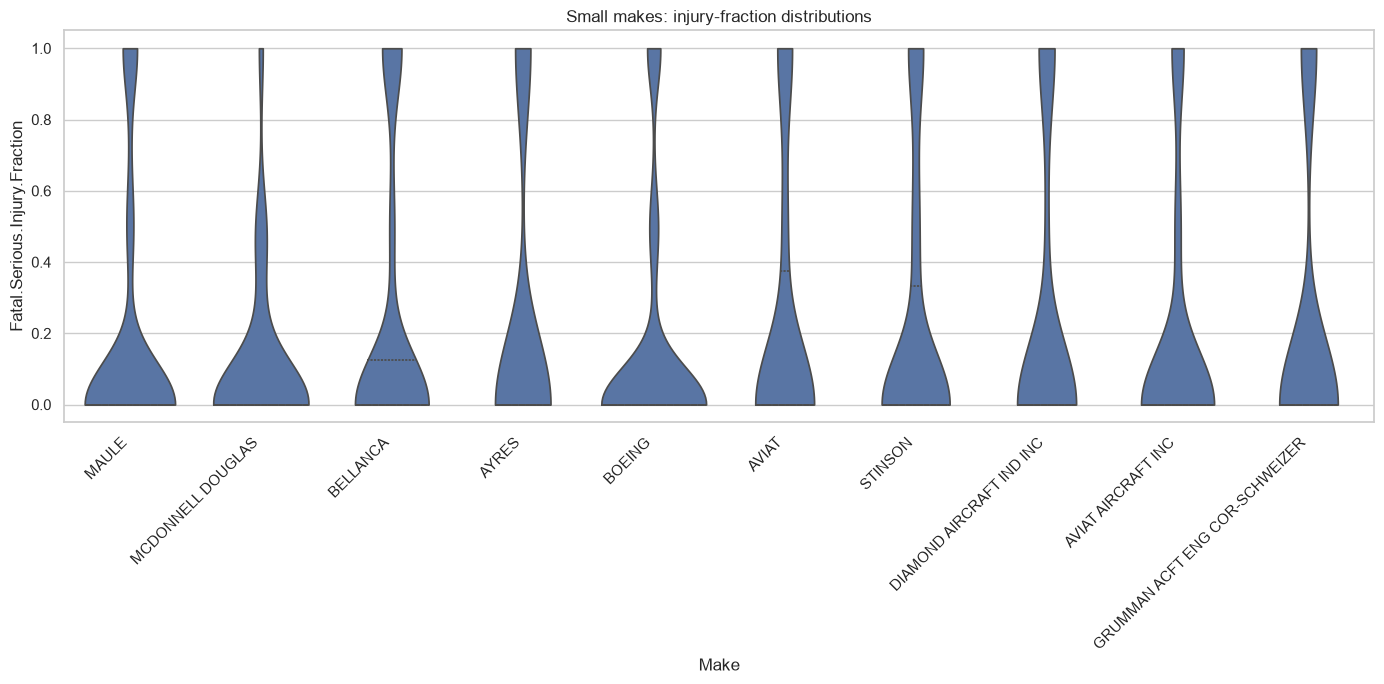

In [41]:
top10=small_make.head(10).index
plt.figure(figsize=(14,7)); sns.violinplot(data=small[small["Make"].isin(top10)],x="Make",y="Fatal.Serious.Injury.Fraction",inner="quartile",cut=0)
plt.xticks(rotation=45,ha="right"); plt.title("Small makes: injury-fraction distributions"); plt.tight_layout(); plt.show()

**Distribution of injury rates: large makes**

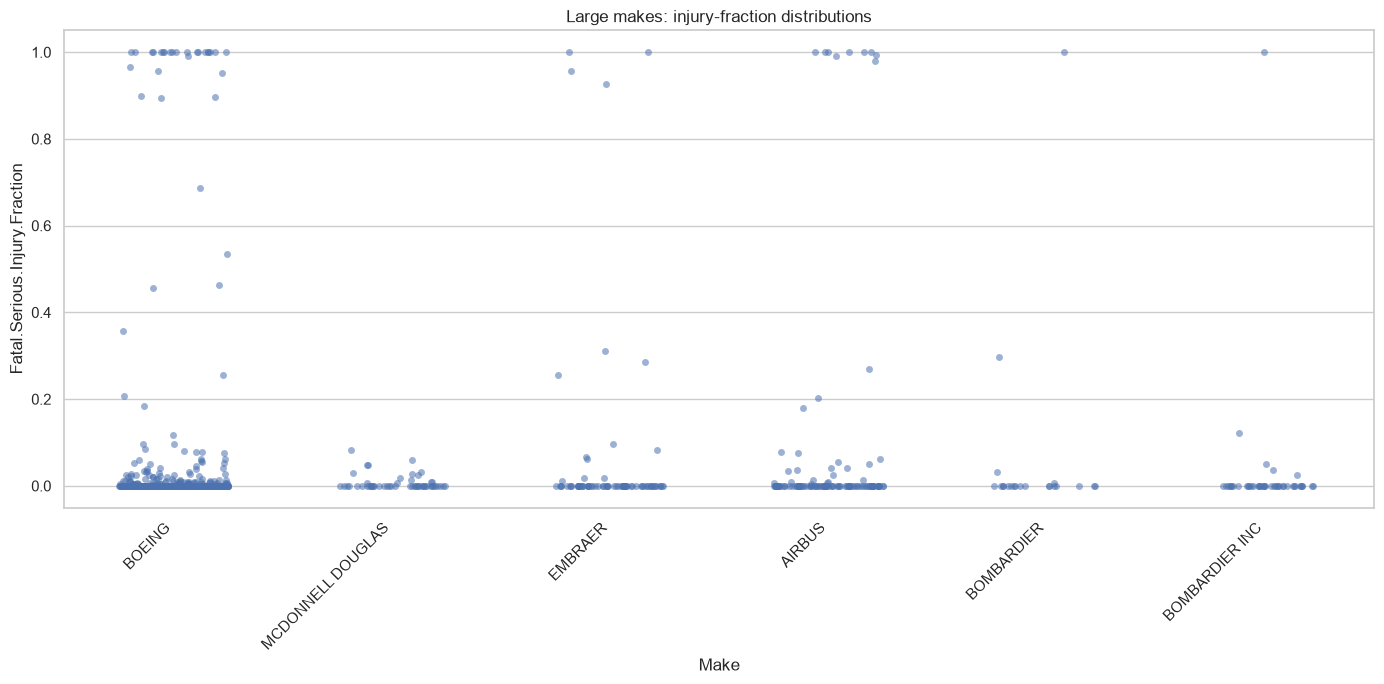

In [42]:
top10=large_make.head(10).index
plt.figure(figsize=(14,7)); sns.stripplot(data=large[large["Make"].isin(top10)],x="Make",y="Fatal.Serious.Injury.Fraction",jitter=.25,alpha=.55)
plt.xticks(rotation=45,ha="right"); plt.title("Large makes: injury-fraction distributions"); plt.tight_layout(); plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.**

,n,mean,std,se,ci95_low,ci95_high
Make,,,,,,
LUSCOMBE,138,0.014493,0.119946,0.010210,0.000000,0.034505
GRUMMAN ACFT ENG COR-SCHWEIZER,58,0.017241,0.131306,0.017241,0.000000,0.051034
STINSON,129,0.023256,0.151302,0.013321,0.000000,0.049366
TAYLORCRAFT,93,0.032258,0.177642,0.018421,0.000000,0.068363
AERONCA,200,0.035000,0.184241,0.013028,0.009466,0.060534
ERCOUPE,52,0.038462,0.194184,0.026928,0.000000,0.091241
AMERICAN CHAMPION AIRCRAFT,51,0.039216,0.196039,0.027451,0.000000,0.093020
AVIAT AIRCRAFT INC,75,0.040000,0.197279,0.022780,0.000000,0.084648
MAULE,215,0.041860,0.200738,0.013690,0.015028,0.068693


,n,mean,std,se,ci95_low,ci95_high
Make,,,,,,
BOMBARDIER INC,27,0.037037,0.192450,0.037037,0.000000,0.109630
EMBRAER,45,0.088889,0.287799,0.042903,0.004800,0.172978
BOEING,279,0.096774,0.296181,0.017732,0.062020,0.131529
MCDONNELL DOUGLAS,36,0.111111,0.318728,0.053121,0.006993,0.215229
AIRBUS,53,0.169811,0.379060,0.052068,0.067758,0.271864


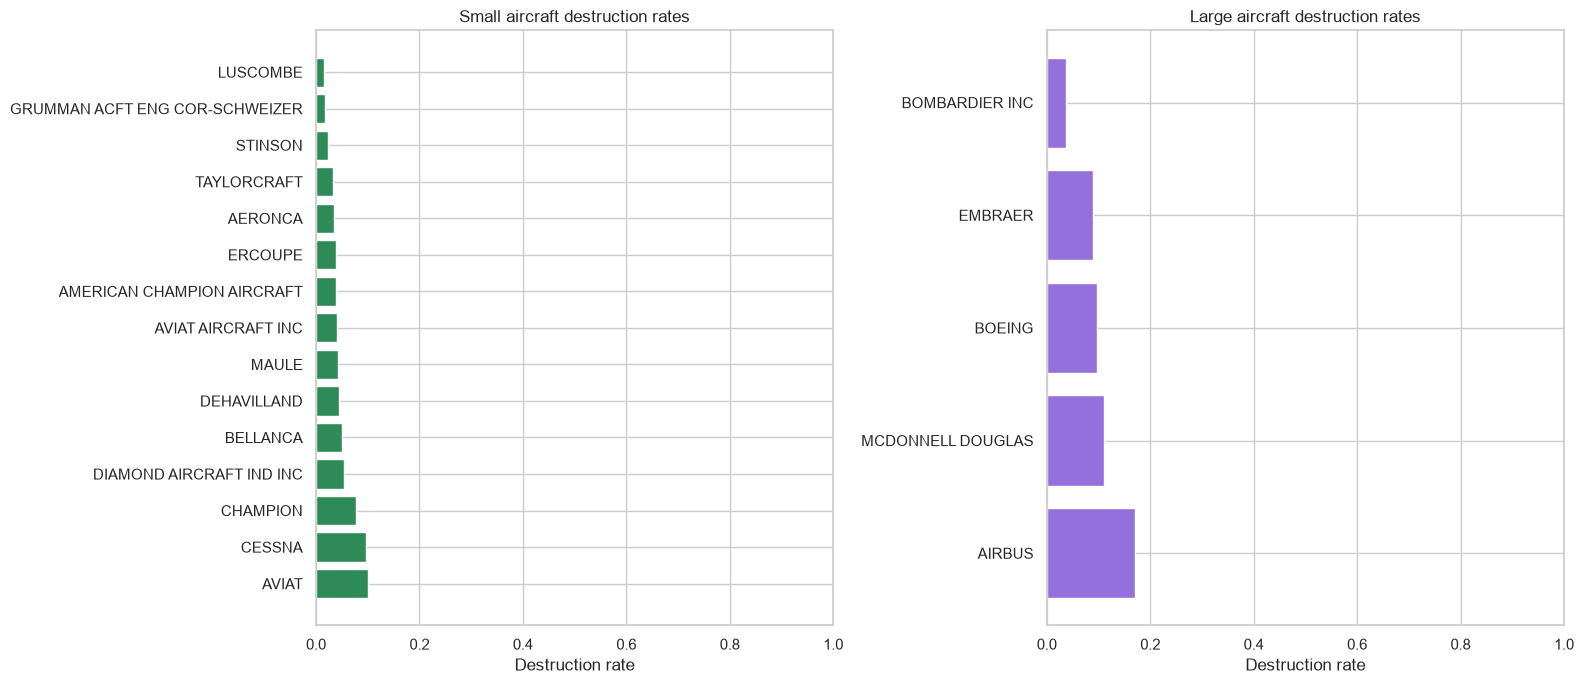

In [43]:
small_damage=grouped_summary(small,"Make","Aircraft.Destroyed",20).head(15)
large_damage=grouped_summary(large,"Make","Aircraft.Destroyed",20).head(15)
display(small_damage); display(large_damage)
fig,axes=plt.subplots(1,2,figsize=(16,7))
for ax,s,title,color in [(axes[0],small_damage,"Small aircraft destruction rates","seagreen"),(axes[1],large_damage,"Large aircraft destruction rates","mediumpurple")]:
    p=s.reset_index().sort_values("mean",ascending=False)
    ax.barh(p["Make"],p["mean"],color=color); ax.set_title(title); ax.set_xlabel("Destruction rate"); ax.set_xlim(0,1)
plt.tight_layout(); plt.show()

#### Provide a short discussion on your findings for your summary statistics and plots:

In [44]:
def recommendations(injury,damage,n=10):
    x=injury[["n","mean","ci95_low","ci95_high"]].rename(columns={"n":"injury_n","mean":"injury_rate","ci95_low":"injury_ci_low","ci95_high":"injury_ci_high"})
    y=damage[["n","mean","ci95_low","ci95_high"]].rename(columns={"n":"damage_n","mean":"destroyed_rate","ci95_low":"damage_ci_low","ci95_high":"damage_ci_high"})
    z=x.join(y,how="inner"); z["combined_score"]=(z["injury_rate"]+z["destroyed_rate"])/2
    return z.sort_values(["combined_score","injury_n"],ascending=[True,False]).head(n)
print("Small-make shortlist"); display(recommendations(small_make,small_damage))
print("Large-make shortlist"); display(recommendations(large_make,large_damage))
print("Lower rates are preferable. Review sample sizes and confidence intervals. These are severity rates conditional on an accident, not accident-frequency rates.")

Small-make shortlist


,injury_n,injury_rate,injury_ci_low,injury_ci_high,damage_n,destroyed_rate,damage_ci_low,damage_ci_high,combined_score
Make,,,,,,,,,
AVIAT AIRCRAFT INC,76,0.164474,0.085756,0.243191,75,0.040000,0.000000,0.084648,0.102237
MAULE,215,0.164806,0.118432,0.211180,215,0.041860,0.015028,0.068693,0.103333
GRUMMAN ACFT ENG COR-SCHWEIZER,58,0.206897,0.101734,0.312059,58,0.017241,0.000000,0.051034,0.112069
STINSON,129,0.216408,0.151284,0.281533,129,0.023256,0.000000,0.049366,0.119832
AERONCA,200,0.225833,0.169829,0.281837,200,0.035000,0.009466,0.060534,0.130417
BELLANCA,219,0.222603,0.169564,0.275642,218,0.050459,0.021335,0.079583,0.136531
DEHAVILLAND,93,0.231652,0.154157,0.309147,89,0.044944,0.001656,0.088231,0.138298
DIAMOND AIRCRAFT IND INC,74,0.222973,0.130322,0.315624,74,0.054054,0.002181,0.105927,0.138514
AVIAT,70,0.221429,0.128670,0.314187,70,0.100000,0.029213,0.170787,0.160714


Large-make shortlist


,injury_n,injury_rate,injury_ci_low,injury_ci_high,damage_n,destroyed_rate,damage_ci_low,damage_ci_high,combined_score
Make,,,,,,,,,
BOMBARDIER INC,44,0.028038,0.000000,0.072752,27,0.037037,0.000000,0.109630,0.032537
MCDONNELL DOUGLAS,53,0.007827,0.003132,0.012522,36,0.111111,0.006993,0.215229,0.059469
BOEING,547,0.056771,0.038855,0.074687,279,0.096774,0.062020,0.131529,0.076772
EMBRAER,78,0.065274,0.016557,0.113991,45,0.088889,0.004800,0.172978,0.077081
AIRBUS,118,0.086249,0.038411,0.134086,53,0.169811,0.067758,0.271864,0.128030


Lower rates are preferable. Review sample sizes and confidence intervals. These are severity rates conditional on an accident, not accident-frequency rates.


### Analyze plane types
Plane type combines make and model. Only groups with at least 10 usable accident records are compared.

**Larger planes**

,n,mean,std,se,ci95_low,ci95_high
Plane.Type,,,,,,
BOEING | 777,33,0.000821,0.002653,0.000462,0.000000,0.001726
BOEING | 757,18,0.001473,0.005073,0.001196,0.000000,0.003816
BOEING | 787,11,0.003058,0.008771,0.002645,0.000000,0.008242
BOEING | 737-7H4,12,0.003242,0.006490,0.001873,0.000000,0.006914
BOMBARDIER INC | CL-600-2B19,15,0.004136,0.011149,0.002879,0.000000,0.009778
EMBRAER | EMB145,11,0.008798,0.029179,0.008798,0.000000,0.026041
EMBRAER | EMB-145LR,15,0.010000,0.026577,0.006862,0.000000,0.023450
BOEING | 747,11,0.023161,0.039878,0.012024,0.000000,0.046728
BOEING | 767,31,0.046963,0.175974,0.031606,0.000000,0.108910


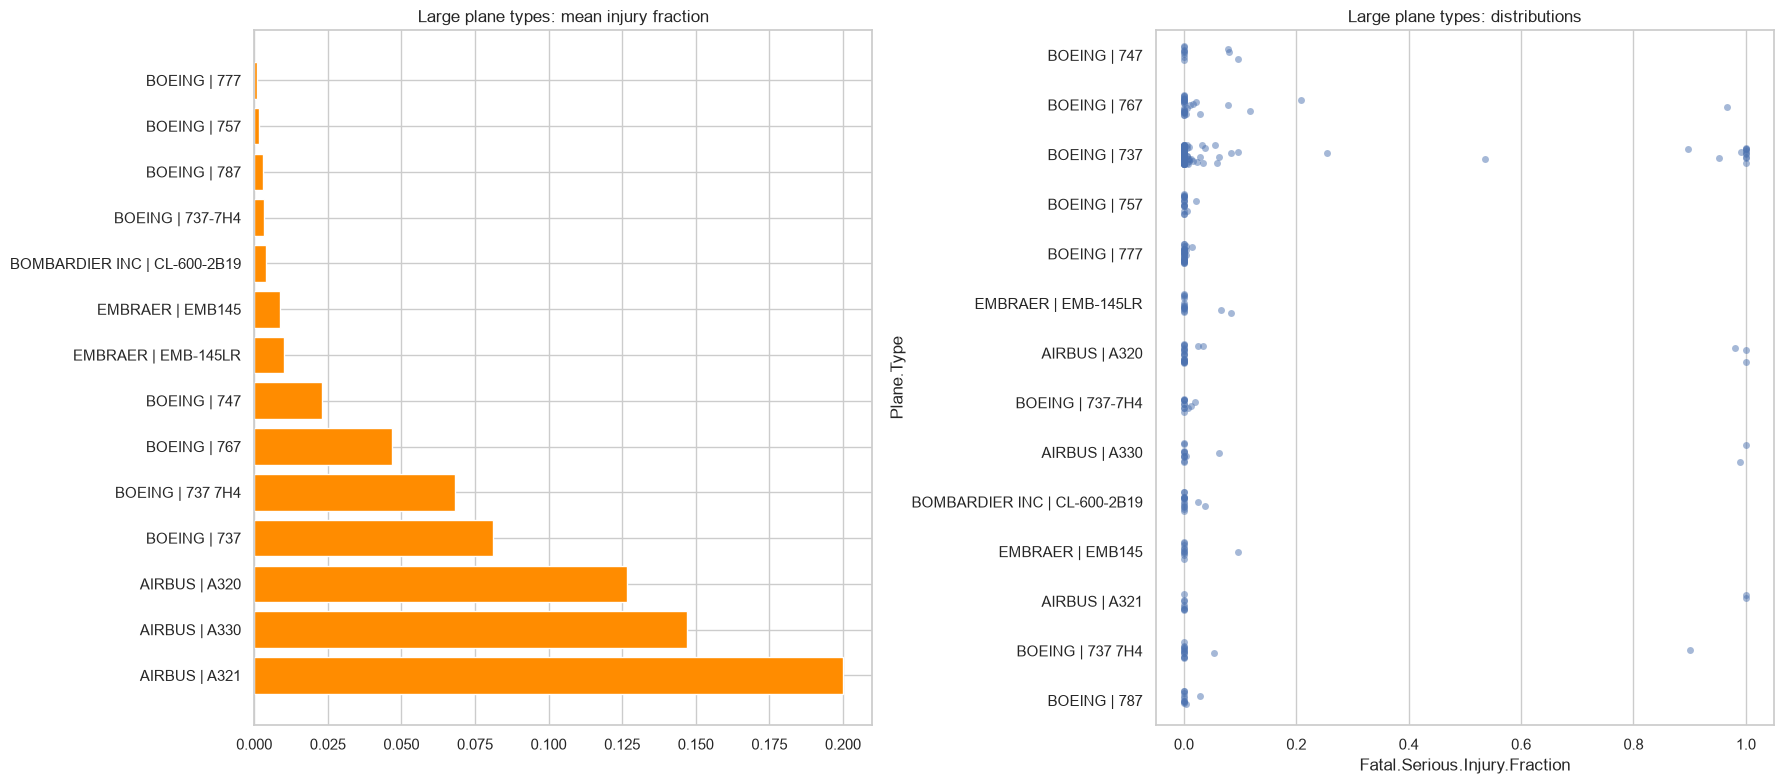

In [45]:
large_type=grouped_summary(large,"Plane.Type","Fatal.Serious.Injury.Fraction",10).head(15)
large_type_damage=grouped_summary(large,"Plane.Type","Aircraft.Destroyed",10)
display(large_type)
p=large_type.reset_index().sort_values("mean",ascending=False)
fig,axes=plt.subplots(1,2,figsize=(18,8)); axes[0].barh(p["Plane.Type"],p["mean"],color="darkorange")
axes[0].set_title("Large plane types: mean injury fraction")
sns.stripplot(data=large[large["Plane.Type"].isin(large_type.index)],y="Plane.Type",x="Fatal.Serious.Injury.Fraction",jitter=.2,alpha=.5,ax=axes[1])
axes[1].set_title("Large plane types: distributions"); plt.tight_layout(); plt.show()

**Smaller planes**
- Results are limited to the 10 lowest mean serious/fatal injury fractions.

,n,mean,std,se,ci95_low,ci95_high
Plane.Type,,,,,,
CESSNA | 172SP,12,0.000000,0.000000,0.000000,0.0,0.000000
DIAMOND AIRCRAFT IND INC | DA 20 C1,11,0.000000,0.000000,0.000000,0.0,0.000000
MAULE | M-5-210C,11,0.000000,0.000000,0.000000,0.0,0.000000
CESSNA | 180J,28,0.035714,0.188982,0.035714,0.0,0.105714
CESSNA | A185E,18,0.038889,0.124328,0.029304,0.0,0.096326
PIPER | PA-20,25,0.040000,0.200000,0.040000,0.0,0.118400
BEECH | B19,16,0.041667,0.166667,0.041667,0.0,0.123333
AIR TRACTOR | AT 602,12,0.041667,0.144338,0.041667,0.0,0.123333
CESSNA | 560XL,21,0.047619,0.218218,0.047619,0.0,0.140952


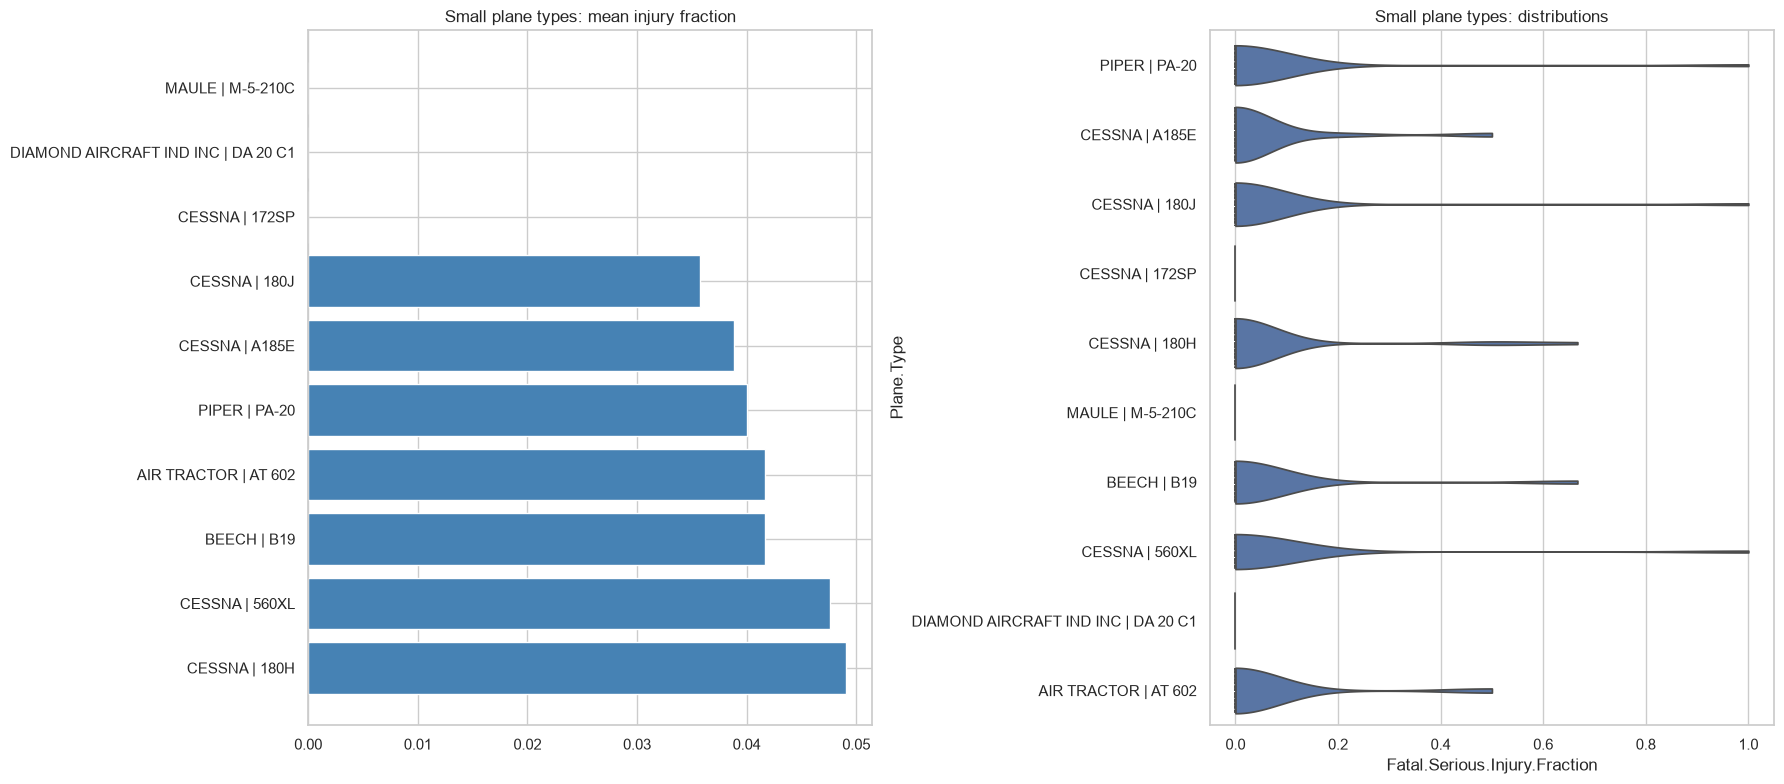

In [46]:
small_type=grouped_summary(small,"Plane.Type","Fatal.Serious.Injury.Fraction",10).head(10)
small_type_damage=grouped_summary(small,"Plane.Type","Aircraft.Destroyed",10)
display(small_type)
p=small_type.reset_index().sort_values("mean",ascending=False)
fig,axes=plt.subplots(1,2,figsize=(18,8)); axes[0].barh(p["Plane.Type"],p["mean"],color="steelblue")
axes[0].set_title("Small plane types: mean injury fraction")
sns.violinplot(data=small[small["Plane.Type"].isin(small_type.index)],y="Plane.Type",x="Fatal.Serious.Injury.Fraction",cut=0,inner="quartile",ax=axes[1])
axes[1].set_title("Small plane types: distributions"); plt.tight_layout(); plt.show()

### Discussion of Specific Airplane Types

In [47]:
print("Small plane-type shortlist"); display(recommendations(small_type,small_type_damage))
print("Large plane-type shortlist"); display(recommendations(large_type,large_type_damage))
print("Prioritize plane types appearing in both outcome tables with low combined scores, sufficient n, and reasonably narrow confidence intervals.")

Small plane-type shortlist


,injury_n,injury_rate,injury_ci_low,injury_ci_high,damage_n,destroyed_rate,damage_ci_low,damage_ci_high,combined_score
Plane.Type,,,,,,,,,
CESSNA | 172SP,12,0.000000,0.0,0.000000,12,0.000000,0.0,0.000000,0.000000
DIAMOND AIRCRAFT IND INC | DA 20 C1,11,0.000000,0.0,0.000000,11,0.000000,0.0,0.000000,0.000000
MAULE | M-5-210C,11,0.000000,0.0,0.000000,11,0.000000,0.0,0.000000,0.000000
CESSNA | 180J,28,0.035714,0.0,0.105714,27,0.000000,0.0,0.000000,0.017857
CESSNA | A185E,18,0.038889,0.0,0.096326,17,0.000000,0.0,0.000000,0.019444
PIPER | PA-20,25,0.040000,0.0,0.118400,25,0.000000,0.0,0.000000,0.020000
BEECH | B19,16,0.041667,0.0,0.123333,16,0.000000,0.0,0.000000,0.020833
AIR TRACTOR | AT 602,12,0.041667,0.0,0.123333,12,0.000000,0.0,0.000000,0.020833
CESSNA | 180H,34,0.049020,0.0,0.103370,34,0.000000,0.0,0.000000,0.024510


Large plane-type shortlist


,injury_n,injury_rate,injury_ci_low,injury_ci_high,damage_n,destroyed_rate,damage_ci_low,damage_ci_high,combined_score
Plane.Type,,,,,,,,,
BOMBARDIER INC | CL-600-2B19,15,0.004136,0.000000,0.009778,11,0.000000,0.000000,0.000000,0.002068
BOEING | 777,33,0.000821,0.000000,0.001726,16,0.062500,0.000000,0.185000,0.031660
BOEING | 767,31,0.046963,0.000000,0.108910,15,0.066667,0.000000,0.197333,0.056815
BOEING | 737,163,0.081223,0.041218,0.121228,97,0.113402,0.049972,0.176832,0.097312


Prioritize plane types appearing in both outcome tables with low combined scores, sufficient n, and reasonably narrow confidence intervals.


### Exploring Other Variables
Weather condition and broad phase of flight are examined. Each displayed category requires at least 50 usable records.

,injury_n,injury_rate,injury_ci_low,injury_ci_high,damage_n,destroyed_rate,damage_ci_low,damage_ci_high
Weather.Condition,,,,,,,,
Vmc,14248,0.233090,0.226491,0.239689,13959,0.072498,0.068196,0.076800
Imc,895,0.628008,0.597562,0.658455,851,0.370153,0.337692,0.402613


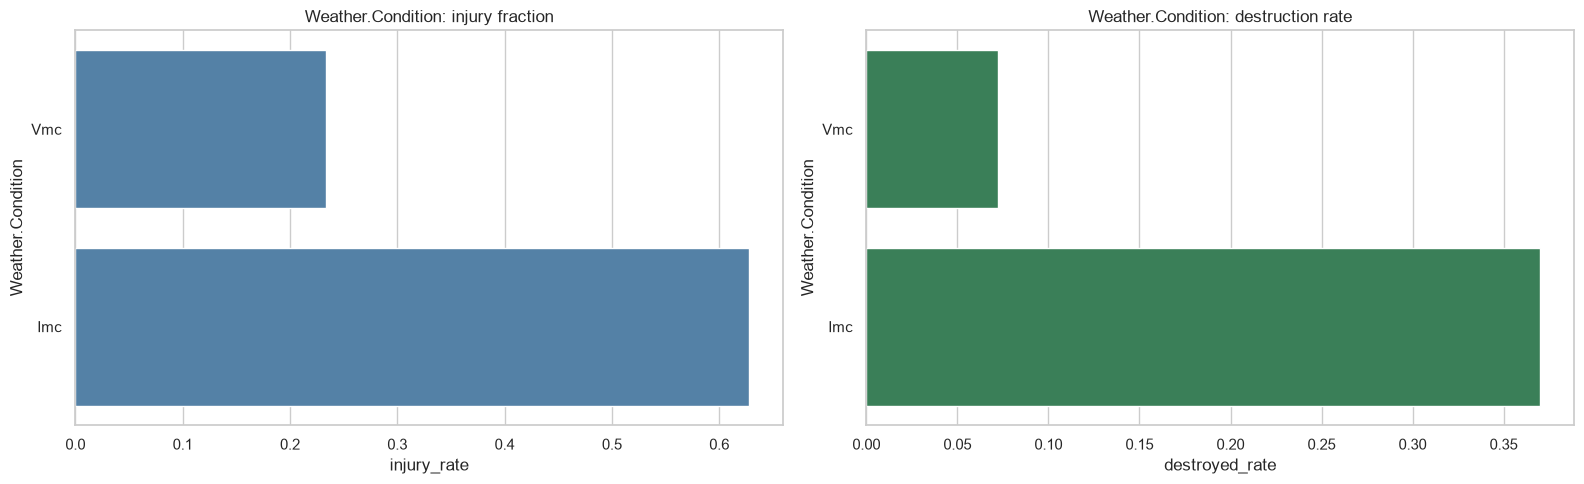

,injury_n,injury_rate,injury_ci_low,injury_ci_high,damage_n,destroyed_rate,damage_ci_low,damage_ci_high
Broad.phase.of.flight,,,,,,,,
Landing,1110,0.008271,0.003395,0.013147,1110,0.012613,0.006045,0.019181
Taxi,99,0.017338,0.000000,0.039678,94,0.010638,0.000000,0.031489
Go-Around,81,0.086831,0.028241,0.145421,81,0.061728,0.008991,0.114466
Takeoff,425,0.108775,0.080687,0.136863,424,0.106132,0.076780,0.135485
Cruise,238,0.182796,0.135078,0.230513,232,0.137931,0.093463,0.182399
Approach,210,0.213239,0.159186,0.267292,208,0.110577,0.067854,0.153299
Descent,62,0.221954,0.121693,0.322215,57,0.175439,0.075821,0.275056
Climb,52,0.317611,0.191353,0.443868,50,0.300000,0.171688,0.428312
Maneuvering,127,0.358704,0.278373,0.439035,127,0.291339,0.211999,0.370678


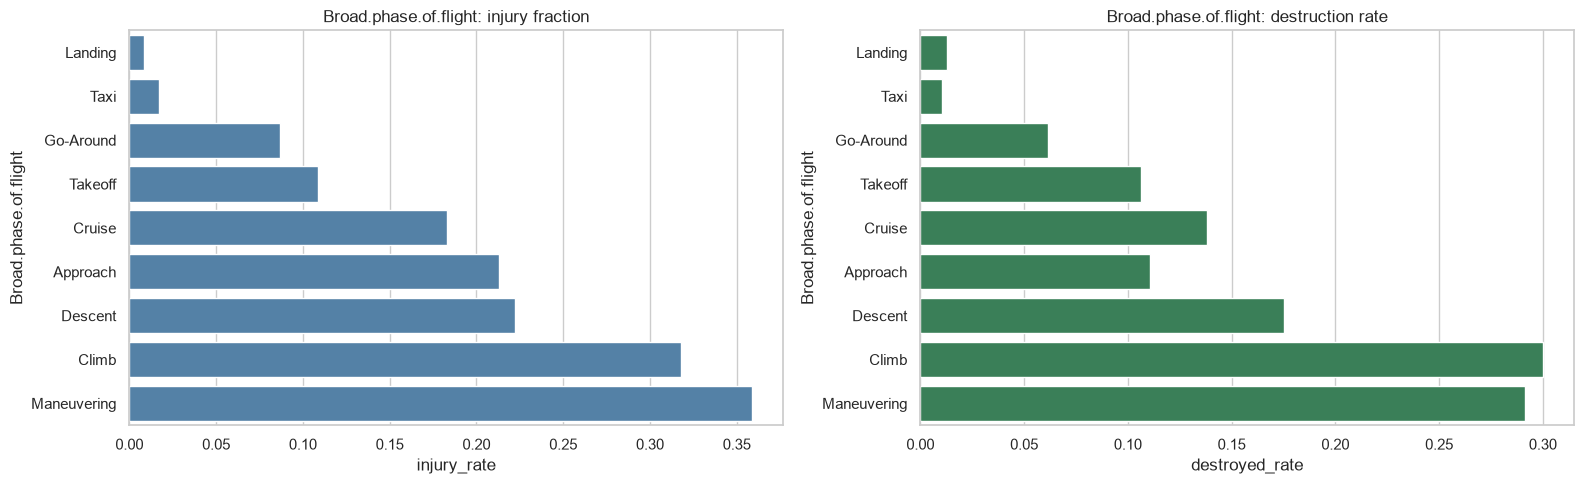

Interpret these as associations, not proof of causation. Exposure counts for all flights are unavailable.


In [48]:
def factor_analysis(data,factor,min_n=50):
    i=grouped_summary(data,factor,"Fatal.Serious.Injury.Fraction",min_n)
    d=grouped_summary(data,factor,"Aircraft.Destroyed",min_n)
    s=i[["n","mean","ci95_low","ci95_high"]].rename(columns={"n":"injury_n","mean":"injury_rate","ci95_low":"injury_ci_low","ci95_high":"injury_ci_high"}).join(
      d[["n","mean","ci95_low","ci95_high"]].rename(columns={"n":"damage_n","mean":"destroyed_rate","ci95_low":"damage_ci_low","ci95_high":"damage_ci_high"}),how="inner")
    display(s); p=s.reset_index(); fig,axes=plt.subplots(1,2,figsize=(16,max(5,.45*len(p))))
    sns.barplot(data=p,y=factor,x="injury_rate",color="steelblue",ax=axes[0]); axes[0].set_title(f"{factor}: injury fraction")
    sns.barplot(data=p,y=factor,x="destroyed_rate",color="seagreen",ax=axes[1]); axes[1].set_title(f"{factor}: destruction rate")
    plt.tight_layout(); plt.show(); return s
weather_summary=factor_analysis(analysis_df,"Weather.Condition")
phase_summary=factor_analysis(analysis_df,"Broad.phase.of.flight")
print("Interpret these as associations, not proof of causation. Exposure counts for all flights are unavailable.")

## Final conclusion and limitations

Based on the aviation accident analysis, the Cessna 172SP is recommended as a leading small-aircraft option. Among the accident records analyzed, it had 12 usable observations, a 0% mean serious/fatal injury fraction, and a 0% aircraft destruction rate. The Diamond Aircraft DA 20 C1 and Maule M-5-210C had similarly favorable results and can be considered alternative small-aircraft options. For large aircraft, the Bombardier Inc CL-600-2B19 is recommended based on its combination of low injury severity and aircraft destruction outcomes. It recorded a serious/fatal injury fraction of approximately 0.41% across 15 observations and a 0% destruction rate across 11 usable damage records, giving it the lowest combined score among the large aircraft make/model combinations assessed. The Boeing 777 is also a strong alternative, particularly on injury outcomes, with a serious/fatal injury fraction of approximately 0.08% across 33 observations, although its destruction rate was 6.25% across 16 usable damage records. In addition to aircraft make and model, the analysis considered weather conditions and phase of flight as factors potentially affecting injury and aircraft damage outcomes. These recommendations should be interpreted with caution because the dataset contains accident records rather than total flight activity or fleet exposure. Therefore, the results indicate the severity of outcomes when an accident occurred and should not be interpreted as the overall probability of an aircraft being involved in an accident. Sample sizes and confidence intervals should also be considered when making final underwriting decisions.